# Markov Chains and Tumor Heterogeneity


## Background

Why are tumors so hard to treat? Why have we been fighting the "War on Cancer" for over 50 years? 

One key reason is that a tumor isn't made up of a single kind of cell. If it was, we could find a single drug that would target said cell, and kill all of them, without them coming back. However, most tumors are mixes of different types of cancer cells. A breast cancer tumor will only contain breast tumor cells, but those breast tumor cells may be clustered in different states-- some of which are sensitive to drugs, some of which are naturally resistant, and some of which can transition from one state to another. In fact, drug treatment is often the *force* that helps tumor cells transition from sensitive to resistant, meaning the treatment itself is worsening the disease it is trying to treat.

## The lab goal: 
>**Simulate a patient's tumor and figure out what combination of drugs is likely to be effective at killing the tumor.**

If we can track how cells change state *within a single tumor* under drugs, then we can predict what might happen to a patient treated with said drug. To answer that we need to know **how often a cell in each state moves to each other state during one treatment cycle**. That is a transition matrix, and a transition matrix lets us forecast what any tumor looks like after many cycles.

In this lab you will:
   
1. **Build a transition matrix.** Use lineage tags to match each cell at time point A to its descendant at time point B, then count and normalize.
2. **Evolve a distribution.** Start from each single state, and from a mixed tumor, and see where each one ends up.
3. **Simulate random walks and whole tumors.** Follow individual cells by drawing random numbers, then simulate many tumors to estimate how likely each one is to be cured or to relapse.
4. **Find which tumors each drug can cure**, and see why a mixed tumor can't be cured by either drug alone.


Note: **The data is simulated.** The states and their marker genes are modelled on PC9 cells (Oren et al. 2021, *Nature* 596:576), but every count was generated by a script, and how each state responds to each drug is vastly simplified.

## The data

**A little background:**

Lung cancer cells carry a mutant EGFR gene and depend on it to grow. We compare two
drugs:

- **osimertinib**, which blocks EGFR, and
- **docetaxel**, a chemotherapy that kills cells while they divide.
- We will also look at how the cells evolve under no treatment ("drug holiday")

You do not need to understand biology or cancer to complete this lab; the key thing is you have drugs with different effects on cells within a single tumor.

**The dataset:**

Every cell carries something called a  **lineage tag**: a short DNA barcode inserted into its genome, inherited by its descendants. For each drug, one sample is:

1. sequenced at **time point A**, before treatment;
2. treated for **one cycle**;
3. sequenced again at **time point B**.

A tag that appears at both time points links a cell at A to its descendant at B. **A tag seen at A but missing at B means that cell died.** We make one big simplifying assumption: each tag maps one cell at A to *at most one* cell at B.


In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

rng = np.random.default_rng(5030)
plt.rcParams["figure.dpi"] = 110

In [2]:
STATE_ORDER = ["S-G1", "S-syn", "S-G2M", "P",
           "NCP", "CP", "MDR"] 
STATE_COLORS = dict(zip(STATE_ORDER, sns.color_palette("Set2", len(STATE_ORDER))))
STATE_COLORS["cleared"] = "#8a8984"  

In [3]:
cells = pd.read_csv("cell_data.csv")
cells.head()

,Unnamed: 0,experiment,timepoint,lineage_tag,umap_x,umap_y,state
0,0,osimertinib,A,tago-02305,12.879967,12.534007,S-G1
1,1,osimertinib,B,tago-01560,-1.712741,11.650750,P
2,2,osimertinib,A,tago-02253,12.870441,12.998882,S-G1
3,3,osimertinib,A,tago-01478,15.319292,1.937557,S-syn
4,4,osimertinib,A,tago-02626,13.258777,12.765258,S-G1


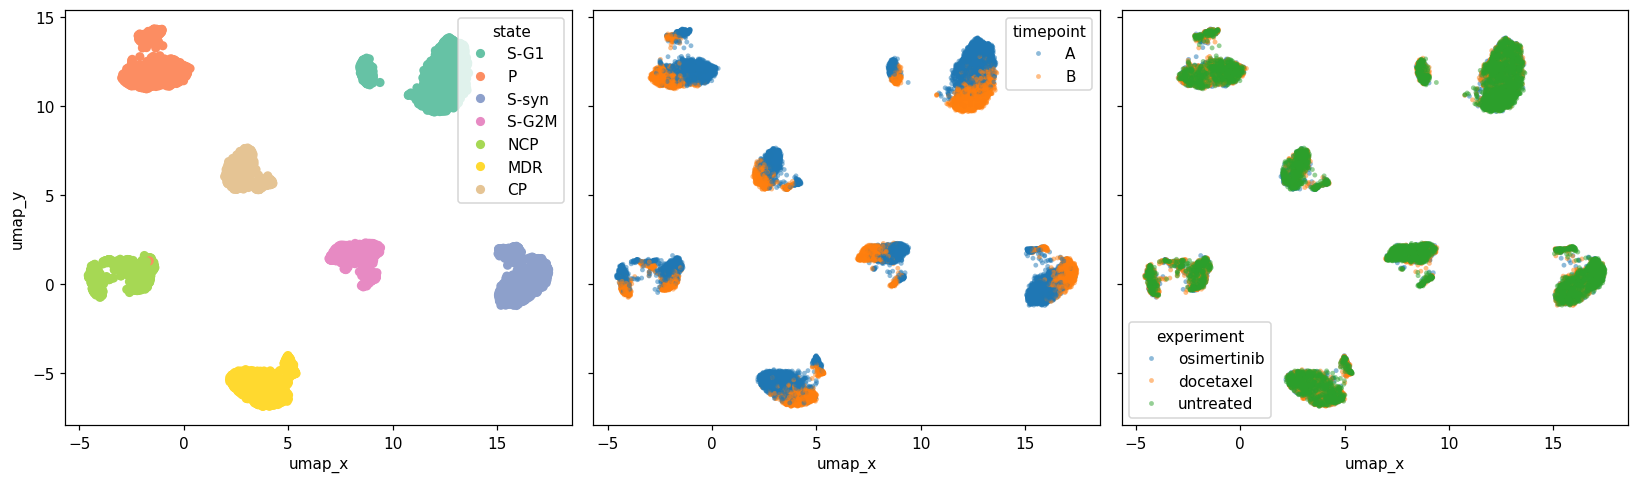

In [4]:
import seaborn as sns
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True, sharey=True)
sns.scatterplot(cells, x = "umap_x", y ="umap_y", hue = "state", ax = axes[0], palette = "Set2", linewidth=0)
sns.scatterplot(cells, x = "umap_x", y ="umap_y", hue = "timepoint", ax = axes[1],s=10, alpha=0.5, linewidth=0)
sns.scatterplot(cells, x = "umap_x", y ="umap_y", hue = "experiment", ax = axes[2],s=10, alpha=0.5, linewidth=0)
plt.tight_layout()
plt.show()

<img src="state_diagram_v2.png">

## 2. Build the transition matrix for the Osimertinib experiment

Start with the osimertinib experiment.

A transition matrix $P$ has one row per state at time point A and one column
per state at time point B:

$$
P_{ij} \;=\; \Pr[\,X_{t+1} = j \mid X_t = i\,]
\;\approx\; \frac{\#\{\text{cells in state } i \text{ at A whose tag is in state } j \text{ at B}\}}
                 {\#\{\text{cells in state } i \text{ at A}\}}.
$$

In the code below, we will start with just the osimertinib experiment (timepoints A and B), and look at where each tag was in A and where it moved to in B. 

**Where does a cell that died end up?** We add an eighth outcome, `"cleared"`, for tags present at A and missing at B.

In [5]:
osi = cells[cells["experiment"] == "osimertinib"]
at_A = osi[osi.timepoint == "A"][["lineage_tag", "state"]]
at_B = osi[osi.timepoint == "B"][["lineage_tag", "state"]]

pairs = pd.merge(at_A, at_B, on="lineage_tag", how="left", suffixes=("_A", "_B"))
pairs["state_B"] = pairs["state_B"].fillna("cleared")

pairs.head()

,lineage_tag,state_A,state_B
0,tago-02305,S-G1,cleared
1,tago-02253,S-G1,cleared
2,tago-01478,S-syn,NCP
3,tago-02626,S-G1,P
4,tago-01487,P,P


In [6]:
STATES = [s for s in STATE_ORDER if s in set(cells["state"])]   # states in a fixed order
OUTCOMES = STATES + ["cleared"]
counts = (pd.crosstab(pairs.state_A, pairs.state_B)
            .reindex(index=STATES, columns=OUTCOMES, fill_value=0))
P_hat = counts.div(counts.sum(axis=1), axis=0)

In [7]:
assert np.allclose(P_hat.sum(axis=1), 1), "Every row should sum to 1."


In [8]:
print("transition counts:")
display(counts)
print("estimated transition matrix (osimertinib, one cycle):")
P_hat.round(3)

transition counts:


state_B,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
state_A,,,,,,,,
S-G1,91,17,11,154,41,0,0,437
S-syn,27,23,17,38,16,0,0,333
S-G2M,8,13,20,20,0,0,0,219
P,47,11,8,160,75,0,0,154
NCP,19,0,0,31,153,0,0,109
CP,0,0,0,0,0,279,0,0
MDR,20,14,10,14,0,0,82,329


estimated transition matrix (osimertinib, one cycle):


state_B,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
state_A,,,,,,,,
S-G1,0.121,0.023,0.015,0.205,0.055,0.0,0.000,0.582
S-syn,0.059,0.051,0.037,0.084,0.035,0.0,0.000,0.733
S-G2M,0.029,0.046,0.071,0.071,0.000,0.0,0.000,0.782
P,0.103,0.024,0.018,0.352,0.165,0.0,0.000,0.338
NCP,0.061,0.000,0.000,0.099,0.490,0.0,0.000,0.349
CP,0.000,0.000,0.000,0.000,0.000,1.0,0.000,0.000
MDR,0.043,0.030,0.021,0.030,0.000,0.0,0.175,0.701


Because some of the cells die and get cleared, we added an extra state they could move to. To use this transition matrix over and over again (for example, if a patient got two rounds of osimertinib), we need it to have the *same* rows and columns-- **the transition matrix should be able to tell us where a cell moves to for *any state at all, including "cleared."*** So we will **add another row to the transition matrix:** if a cell starts in "cleared" it stays cleared with probability = 1.

### Make it square

We add that row by **assumption**: a cleared cell stays cleared with probability 1. A state you can never leave is called an **absorbing state**.

In [9]:
#add a cleared row that stays cleared with p = 1
P_hat.loc["cleared"] = pd.Series({rowname: (1 if rowname == "cleared" else 0) for rowname in P_hat.columns})

In [10]:
STATES = [s for s in STATE_ORDER if s in set(cells["state"])]
OUTCOMES = STATES + ["cleared"]

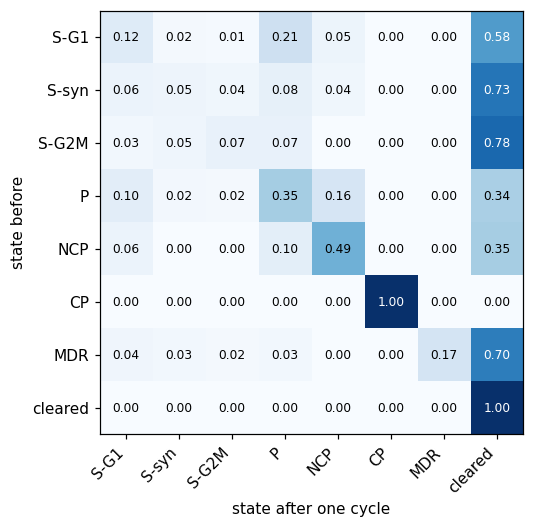

In [11]:
def show_matrix(P, title=None, ax=None):
    ax = ax or plt.subplots(figsize=(6.5, 5))[1]
    values = P.to_numpy()                      # numbers for imshow and P[i, j]
    ax.imshow(values, cmap="Blues", vmin=0, vmax=1)
    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            ax.text(j, i, f"{values[i, j]:.2f}", ha="center", va="center",
                    color="white" if values[i, j] > 0.5 else "black", fontsize=8)
    ax.set_xticks(range(values.shape[1]), P.columns, rotation=45, ha="right")
    ax.set_yticks(range(values.shape[0]), P.index)
    ax.set_xlabel("state after one cycle"); ax.set_ylabel("state before")
    ax.set_title(title)

show_matrix(P_hat)

<div class='alert alert-info'>
<b>Question:</b> reading P_hat and looking at the matrix, are any of the measured states other than "cleared" also (approximately) absorbing under osimertinib? If so, what does this mean in terms of the response to drug treatment? If not, what does it mean?
</div>

Yes. CP is an absorbing state under osimertinib because its probability of remaining in CP is 1. This means CP cells are resistant to osimertinib and cannot be cleared by this treatment in our model. Therefore, tumors containing CP cells cannot be completely eliminated by osimertinib alone.

## 3. Simulate a tumor comprising 1 cell type: Evolve a distribution

Write the state of the whole tumor as a **row vector** $\pi_t$: entry $j$ is the
probability that a randomly chosen original cell is in state $j$ after $t$
cycles. One cycle multiplies by $P$:

$$
\pi_{t+1} = \pi_t P
\qquad\Longrightarrow\qquad
\pi_t = \pi_0 P^t .
$$

Start with the simplest $\pi_0$: a **basis vector**, all probability on one
state. $e = (1, 0, 0, 0, 0, 0, 0, 0)$ asks "what happens to a
cell that starts in state S-G1?" Equivalently, "what happens to a tumor made entirely of S-G1 cells?"

**Predict first.** Before running the code: look at the transition matrix: which starting states can osimertinib eliminate completely? Which can't it? 

In [12]:
def evolve(pi0, P, n_cycles):
    '''Return an array of shape (n_cycles + 1, n_states) whose row t is pi0 @ P^t.'''
    traj = [np.asarray(pi0, dtype=float)]
    for _ in range(n_cycles):
        traj.append(traj[-1] @ P)
    return np.array(traj)

In [13]:
def basis(starting_state, P):
    '''All probability on one state, named as in P's columns.'''
    names = list(P.columns)
    e = np.zeros(len(names))
    e[names.index(starting_state)] = 1.0
    return e

basis("S-G1", P_hat)

array([1., 0., 0., 0., 0., 0., 0., 0.])

### What happens after many rounds of a single treatment?
We are going to run 8 rounds of treatment. A typical course of chemotherapy is 4 to 8 rounds, so this is on the higher end. With 8 rounds, do we clear all of the cancer cells?

In [14]:
traj = evolve(basis("S-G1", P_hat), P_hat, 8)
pd.DataFrame(traj, columns=OUTCOMES).round(3)

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,1.000,0.000,0.000,0.000,0.000,0.0,0.0,0.000
1,0.121,0.023,0.015,0.205,0.055,0.0,0.0,0.582
2,0.041,0.010,0.007,0.105,0.068,0.0,0.0,0.769
3,0.021,0.004,0.003,0.054,0.053,0.0,0.0,0.865
4,0.012,0.002,0.002,0.029,0.036,0.0,0.0,0.919
5,0.007,0.001,0.001,0.016,0.023,0.0,0.0,0.951
6,0.004,0.001,0.000,0.010,0.015,0.0,0.0,0.971
7,0.002,0.000,0.000,0.006,0.009,0.0,0.0,0.982
8,0.001,0.000,0.000,0.003,0.005,0.0,0.0,0.989


The output of the evolve function is a dataframe where columns are the states and each row is the distribution of probability after that many cycles. We can also visualize this in the plots below. 

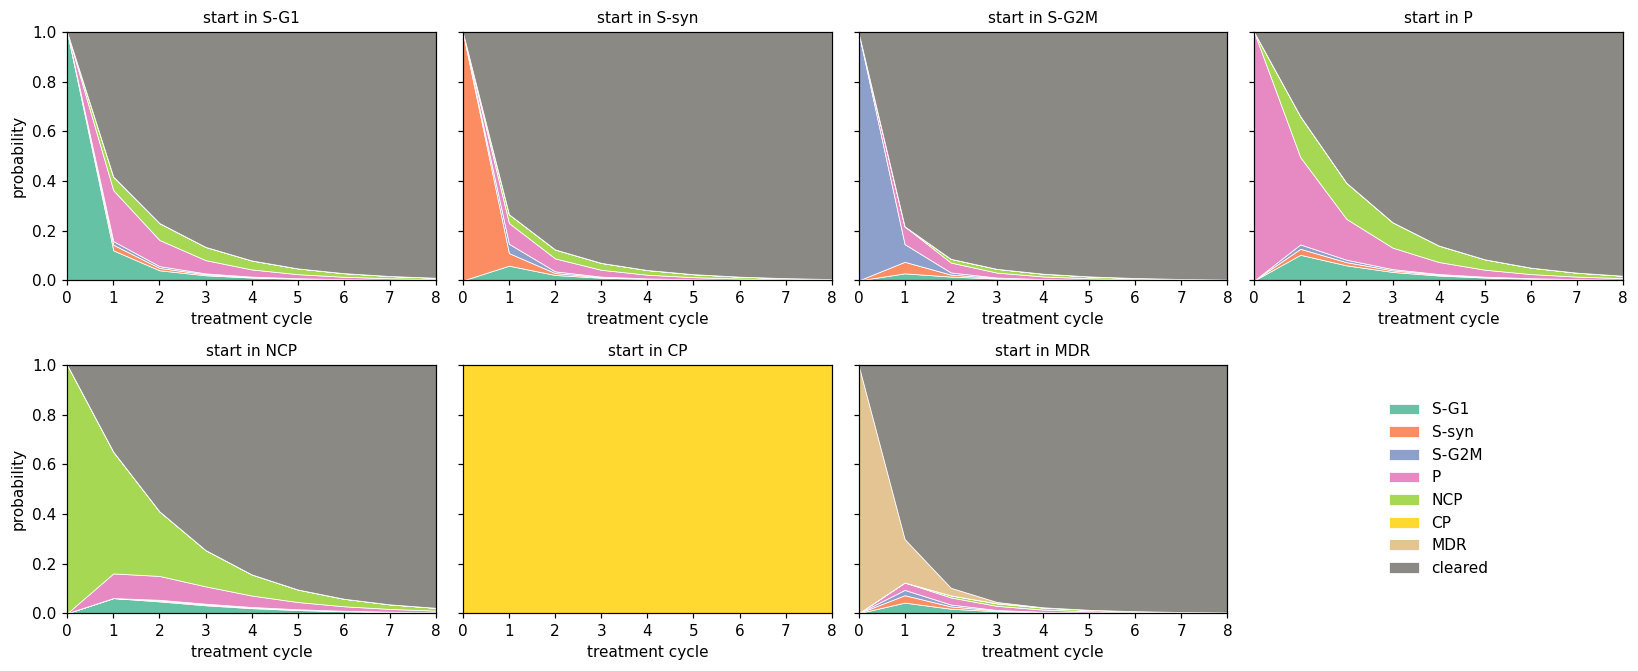

fraction alive after 4 cycles, starting in S-G1 : 0.081
fraction alive after 4 cycles, starting in S-syn : 0.042
fraction alive after 4 cycles, starting in S-G2M : 0.027
fraction alive after 4 cycles, starting in P : 0.141
fraction alive after 4 cycles, starting in NCP : 0.156
fraction alive after 4 cycles, starting in CP : 1.0
fraction alive after 4 cycles, starting in MDR : 0.024
fraction alive after 4 cycles, starting in cleared : 0.0


In [15]:
def plot_trajectory(traj, ax, title):
    t = np.arange(len(traj))
    ax.stackplot(t, traj.T, labels=OUTCOMES, colors=[STATE_COLORS[o] for o in OUTCOMES],
                 edgecolor="white", linewidth=0.5)
    ax.set_xlim(0, t[-1]); ax.set_ylim(0, 1)
    ax.set_title(title, fontsize=10); ax.set_xlabel("treatment cycle")

N_CYCLES = 8
fig, axes = plt.subplots(2, 4, figsize=(15, 6.2), sharey=True)
for ax, s in zip(axes.flat, STATES):
    plot_trajectory(evolve(basis(s, P_hat), P_hat, N_CYCLES), ax, f"start in {s}")

axes.flat[-1].axis("off")                                   # 7 states, 8 panels: use the last one for the legend
handles, labels = axes.flat[0].get_legend_handles_labels()
axes.flat[-1].legend(handles, labels, loc="center", frameon=False)

for ax in axes[:, 0]:
    ax.set_ylabel("probability")
plt.tight_layout()
plt.show()

alive3 = {s: 1 - evolve(basis(s, P_hat), P_hat, 4)[-1, -1] for s in OUTCOMES}
for s,v in alive3.items():
    print("fraction alive after 4 cycles, starting in", s, ":", round(v, 3))

<div class='alert alert-info'>
Use code as appropriate to answer the following questions.

- Which starting states does osimertinib completely eliminate (all probability ends in `cleared`)? Which ones survive?
- Of the states that can be cleared, which tumor lasts the longest?
- Which starting state sticks around for the most cycles of drug?
- Which starting state results in the highest proportion of alive cells after three cycles?</div>



- Osimertinib eventually eliminates S-G1, S-syn, S-G2M, P, NCP, and MDR with probability approaching 1. CP survives because it is an absorbing state.

- NCP lasts the longest among the clearable states because its survival probability decreases the most slowly.

- CP persists for the most cycles because it remains in CP with probability 1.

- CP has the highest survival probability after three cycles. Among the clearable states, NCP has the highest survival probability.

### Starting from a mix of cell types
Use the distribution of states in timepoint A across all three experiments as a starting vector, $\pi_{0}$. Use this as your starting vector to evolve, and plot the result.

[0.247      0.14833333 0.09944444 0.15255556 0.10244444 0.09722222
 0.153      0.        ]
Sum: 1.0


,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,0.247,0.148,0.099,0.153,0.102,0.097,0.153,0.000
1,0.070,0.026,0.022,0.139,0.094,0.097,0.027,0.525
2,0.032,0.008,0.007,0.077,0.074,0.097,0.005,0.701
3,0.017,0.003,0.003,0.042,0.051,0.097,0.001,0.786
4,0.010,0.002,0.001,0.024,0.033,0.097,0.000,0.833
5,0.006,0.001,0.001,0.014,0.021,0.097,0.000,0.861
6,0.003,0.001,0.000,0.008,0.013,0.097,0.000,0.877
7,0.002,0.000,0.000,0.005,0.008,0.097,0.000,0.887
8,0.001,0.000,0.000,0.003,0.005,0.097,0.000,0.893


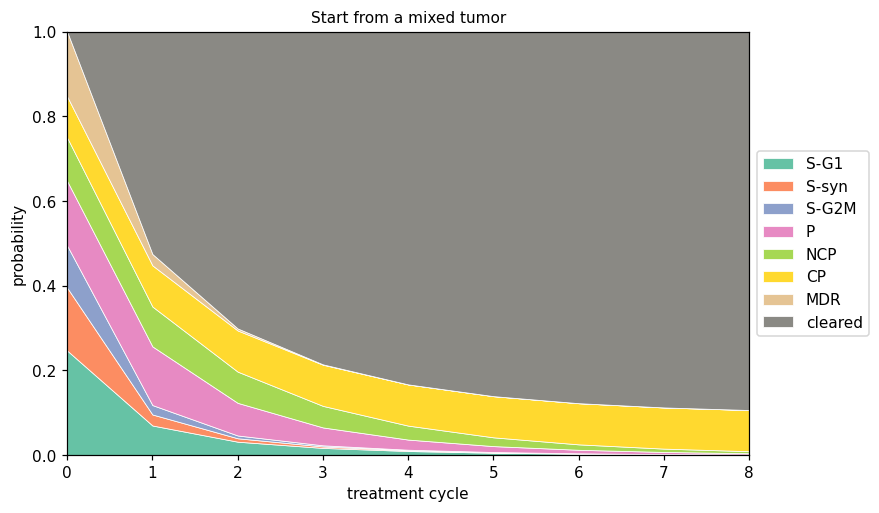

In [17]:
initial_counts = (
    cells[cells["timepoint"] == "A"]["state"]
    .value_counts()
    .reindex(STATES, fill_value=0)
)

pi_mix = (
    initial_counts / initial_counts.sum()
).reindex(OUTCOMES, fill_value=0).to_numpy()

print(pi_mix)
print("Sum:", pi_mix.sum())

# evolve pi_mix and plot the results
traj_mix = evolve(pi_mix, P_hat, 8)

display(pd.DataFrame(traj_mix, columns=OUTCOMES).round(3))

fig, ax = plt.subplots(figsize=(8, 5))
plot_trajectory(traj_mix, ax, "Start from a mixed tumor")
ax.set_ylabel("probability")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.show()

<div class = "alert alert-info"> Which state ends up dominating the remaining cluster? Will these cells ever be cleared? How does the long-run endpoint relate to the transition matrix?</div>

CP ends up dominating the remaining tumor because it is an absorbing state under osimertinib. These cells will not be cleared by osimertinib. In the long run, the probability distribution stabilizes at 9.7% CP and 90.3% cleared. This is because CP and cleared are the two absorbing states in the transition matrix, so probability accumulates in these states and remains there.

## 4. Transition matrices for docetaxel and the drug holiday

Using the same approach in step 2 and step 3, answer the following questions.

1. What is the transition matrix under docetaxel and drug holiday, and how do they compare to osimertinib? Are there any absorbing states?
2. Simulate the mixed tumor under multiple rounds of docetaxel. What happens?

In [20]:
def build_transition_matrix(experiment):
    data = cells[cells["experiment"] == experiment]

    at_A = data[data["timepoint"] == "A"][["lineage_tag", "state"]]
    at_B = data[data["timepoint"] == "B"][["lineage_tag", "state"]]

    pairs = pd.merge(
        at_A, at_B,
        on="lineage_tag",
        how="left",
        suffixes=("_A", "_B")
    )
    pairs["state_B"] = pairs["state_B"].fillna("cleared")

    counts = pd.crosstab(pairs["state_A"], pairs["state_B"])
    counts = counts.reindex(
        index=STATES,
        columns=OUTCOMES,
        fill_value=0
    )

    P = counts.div(counts.sum(axis=1), axis=0)

    P.loc["cleared"] = [
        1.0 if s == "cleared" else 0.0
        for s in OUTCOMES
    ]

    return P.reindex(index=OUTCOMES, columns=OUTCOMES)


P_osi = P_hat.to_numpy()
P_doc_df = build_transition_matrix("docetaxel")
P_holiday_df = build_transition_matrix("untreated")

P_doc = P_doc_df.to_numpy()
P_holiday = P_holiday_df.to_numpy()

print("Docetaxel transition matrix:")
display(P_doc_df.round(3))

print("Drug holiday transition matrix:")
display(P_holiday_df.round(3))


Docetaxel transition matrix:


state_B,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
state_A,,,,,,,,
S-G1,0.293,0.102,0.020,0.091,0.082,0.0,0.035,0.376
S-syn,0.050,0.111,0.136,0.050,0.032,0.0,0.000,0.620
S-G2M,0.028,0.025,0.035,0.021,0.021,0.0,0.000,0.870
P,0.090,0.040,0.021,0.409,0.073,0.0,0.015,0.352
NCP,0.075,0.000,0.003,0.094,0.436,0.0,0.022,0.370
CP,0.079,0.034,0.034,0.028,0.000,0.1,0.000,0.724
MDR,0.000,0.000,0.000,0.000,0.000,0.0,1.000,0.000
cleared,0.000,0.000,0.000,0.000,0.000,0.0,0.000,1.000


Drug holiday transition matrix:


state_B,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
state_A,,,,,,,,
S-G1,0.412,0.431,0.107,0.000,0.000,0.00,0.000,0.050
S-syn,0.093,0.342,0.517,0.000,0.000,0.00,0.000,0.048
S-G2M,0.571,0.100,0.269,0.000,0.000,0.00,0.000,0.060
P,0.413,0.100,0.054,0.324,0.045,0.00,0.002,0.061
NCP,0.186,0.069,0.000,0.227,0.478,0.00,0.000,0.041
CP,0.059,0.033,0.036,0.000,0.000,0.82,0.000,0.052
MDR,0.319,0.044,0.044,0.000,0.000,0.00,0.542,0.051
cleared,0.000,0.000,0.000,0.000,0.000,0.00,0.000,1.000


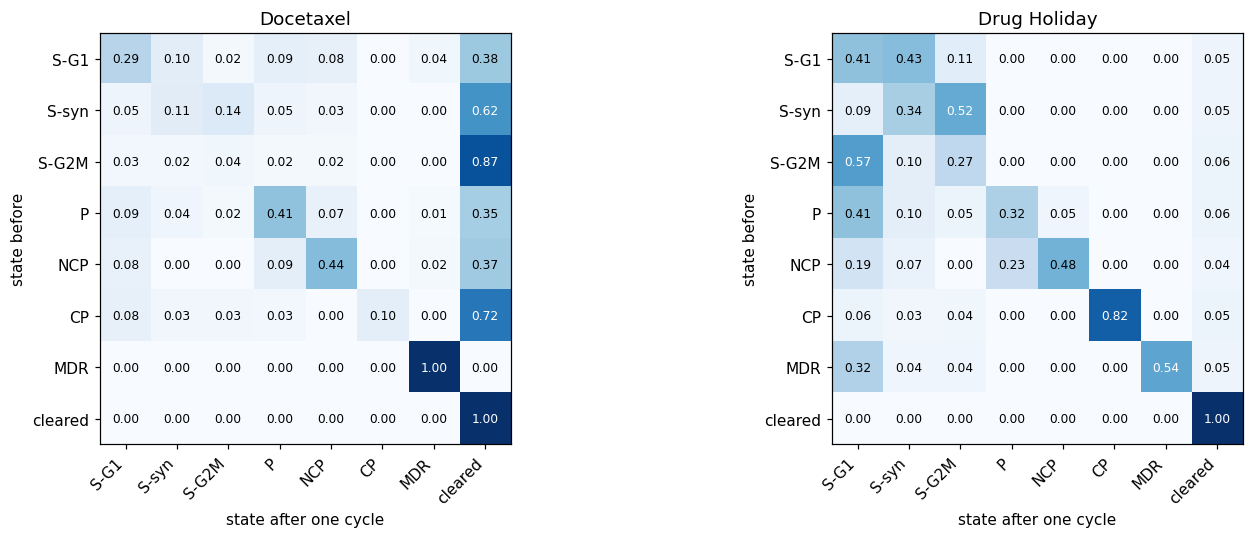

In [21]:
#Plot the transition matrices for docetaxel and the drug holiday.

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

show_matrix(P_doc_df, "Docetaxel", ax=axes[0])
show_matrix(P_holiday_df, "Drug Holiday", ax=axes[1])

plt.tight_layout()
plt.show()

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,0.247,0.148,0.099,0.153,0.102,0.097,0.153,0.000
1,0.112,0.054,0.036,0.107,0.083,0.010,0.166,0.434
2,0.053,0.023,0.014,0.065,0.055,0.001,0.174,0.615
3,0.027,0.011,0.006,0.038,0.034,0.000,0.178,0.705
4,0.015,0.006,0.003,0.022,0.020,0.000,0.180,0.754
5,0.008,0.003,0.002,0.013,0.012,0.000,0.181,0.781
6,0.005,0.002,0.001,0.007,0.007,0.000,0.182,0.797
7,0.003,0.001,0.001,0.004,0.004,0.000,0.182,0.805
8,0.002,0.001,0.000,0.002,0.002,0.000,0.183,0.810


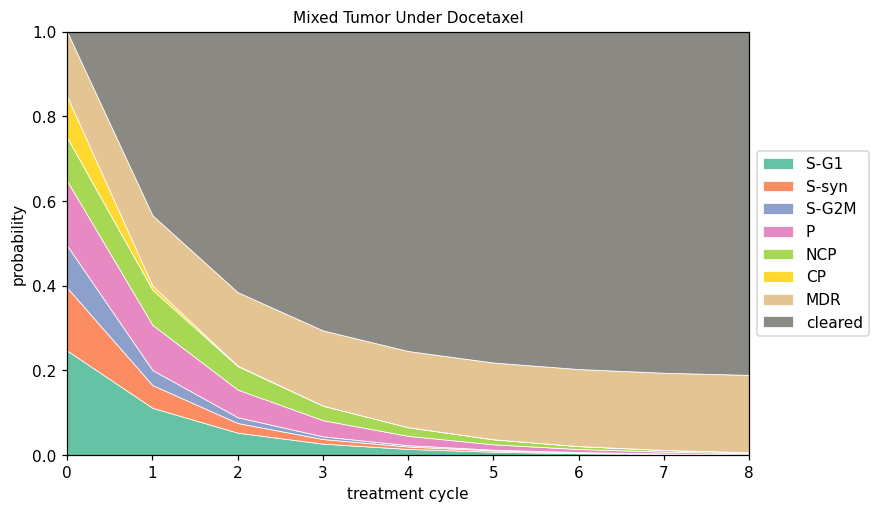

In [22]:
# Simulate the evolution of pi_mix under docetaxel 
N_CYCLES = 8

traj_doc = evolve(pi_mix, P_doc, N_CYCLES)

display(pd.DataFrame(
    traj_doc,
    columns=OUTCOMES
).round(3))

fig, ax = plt.subplots(figsize=(8, 5))

plot_trajectory(traj_doc, ax, "Mixed Tumor Under Docetaxel")

ax.set_ylabel("probability")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))

plt.show()

- The transition matrices show different effects across treatments. Under osimertinib, CP is an absorbing state, while under docetaxel, MDR is an absorbing state. Docetaxel can clear 72.4% of CP cells in one cycle, while osimertinib can clear 70.1% of MDR cells. Under the drug holiday, cleared is the only absorbing state. Cells can transition between different states without treatment, and the cleared probabilities are much lower than under either drug.
- Under repeated docetaxel treatment, the cleared probability increases to 81.0% after eight cycles. However, MDR gradually becomes the dominant surviving state because it is absorbing under docetaxel. Some other states can also transition into MDR, so docetaxel alone cannot completely eliminate the mixed tumor.

## 5. Drug schedule strategies

We can answer a LOT of questions about what treatment strategy is best, just based on multiplying the transition matrices $P_{osi}, P_{doc},$ and $P_{holiday}$ together. Because matrix multiplication is linear, knowing what happens to the basis vectors under each drug tells us everything we need to know about the possibilities for mixed tumors. Use the transition matrices to do the following, running **8 cycles in each schedule**:
1. Compare 8 rounds of docetaxel and 8 rounds of osimertinib (done in step 4) to an alternating drug schedule.
   - For an alternating schedule, one *pair* of cycles multiplies by $P_{osi} P_{doc}$ and is considered 2 rounds of therapy.
2. Does it matter if we start with osimertinib or docetaxel when alternating treatments for this particular tumor?
3.  In what situation would a drug holiday help clear the tumor?
4. Test different combinations of starting states and treatment plans. Write a treatment prescription based on the general patterns you see. For example, If a tumor is entirely X cell type, treat with X. You do not need to enumerate the entire state space of possibilities, but a few clear strategies should emerge. In your treatment prescription, include the number of rounds of therapy needed. Keep in mind that fewer rounds is always better for patient health, but may not sufficiently clear the tumor. You can write this as a table or a short paragraph, but include your reasoning.

In [23]:
N = 8

schedules = {
    "Osimertinib only": [P_osi] * N,
    "Docetaxel only": [P_doc] * N,
    "Alternating O-D": [P_osi, P_doc] * 4,
    "Alternating D-O": [P_doc, P_osi] * 4
}

results = []

for name, schedule in schedules.items():
    pi = pi_mix.copy()

    for P in schedule:
        pi = pi @ P

    results.append({
        "Schedule": name,
        "Cleared": pi[OUTCOMES.index("cleared")],
        "Alive": 1 - pi[OUTCOMES.index("cleared")],
        "CP": pi[OUTCOMES.index("CP")],
        "MDR": pi[OUTCOMES.index("MDR")]
    })

comparison = pd.DataFrame(results)
display(comparison.round(4))

,Schedule,Cleared,Alive,CP,MDR
0,Osimertinib only,0.8934,0.1066,0.0972,0.0000
1,Docetaxel only,0.8104,0.1896,0.0000,0.1826
2,Alternating O-D,0.9906,0.0094,0.0000,0.0007
3,Alternating D-O,0.9908,0.0092,0.0000,0.0003


1. Alternating osimertinib and docetaxel is more effective than using either drug alone. After eight cycles, alternating treatment clears approximately 99.1% of the tumor, compared with 89.3% for osimertinib alone and 81.0% for docetaxel alone. Because the two drugs target different resistant states.

2. The starting drug makes very little difference for this mixed tumor. Starting with docetaxel gives a slightly higher clearance probability (99.08%) than starting with osimertinib (99.06%). Although matrix multiplication depends on order, the difference here is negligible.

In [24]:
pi_mdr = basis("MDR", P_hat)

holiday_schedules = {
    "Docetaxel only": [P_doc] * 8,
    "Holiday only": [P_holiday] * 8,
    "Holiday then Docetaxel": [P_holiday] * 4 + [P_doc] * 4,
    "Alternating Holiday-Docetaxel": [P_holiday, P_doc] * 4
}

rows = []

for name, schedule in holiday_schedules.items():
    pi = pi_mdr.copy()

    for P in schedule:
        pi = pi @ P

    rows.append({
        "Schedule": name,
        "Cleared": pi[OUTCOMES.index("cleared")],
        "Alive": 1 - pi[OUTCOMES.index("cleared")]
    })

holiday_results = pd.DataFrame(rows)
display(holiday_results.round(4))


,Schedule,Cleared,Alive
0,Docetaxel only,0.0000,1.0000
1,Holiday only,0.3457,0.6543
2,Holiday then Docetaxel,0.8541,0.1459
3,Alternating Holiday-Docetaxel,0.7982,0.2018


3. A drug holiday can help when the tumor contains drug resistant cells that may return to sensitive states without treatment. For example, MDR is absorbing under docetaxel, so eight cycles of docetaxel alone clear none of the MDR only tumor. However, four cycles of drug holiday followed by four cycles of docetaxel clear approximately 85.4% in our simulation. This happens because some MDR cells transition back to sensitive states during the holiday, making them susceptible to subsequent treatment.

In [25]:
starting_states = ["S-G1", "P", "NCP", "CP", "MDR"]

schedules = {
    "Osimertinib only": [P_osi] * 8,
    "Docetaxel only": [P_doc] * 8,
    "Alternating O-D": [P_osi, P_doc] * 4,
    "Alternating D-O": [P_doc, P_osi] * 4,
    "Holiday then Docetaxel": [P_holiday] * 4 + [P_doc] * 4
}

results = []

for state in starting_states:
    for name, schedule in schedules.items():
        pi = basis(state, P_hat)
        rounds_to_95 = None

        for cycle, P in enumerate(schedule, start=1):
            pi = pi @ P
            if rounds_to_95 is None and pi[-1] >= 0.95:
                rounds_to_95 = cycle

        results.append({
            "Starting State": state,
            "Schedule": name,
            "Cleared after 8": pi[-1],
            "Cycles to 95%": rounds_to_95
        })

prescription_results = pd.DataFrame(results)

display(prescription_results.round(3))


,Starting State,Schedule,Cleared after 8,Cycles to 95%
0,S-G1,Osimertinib only,0.989,5.0
1,S-G1,Docetaxel only,0.927,NaN
2,S-G1,Alternating O-D,0.990,5.0
3,S-G1,Alternating D-O,0.989,6.0
4,S-G1,Holiday then Docetaxel,0.935,NaN
5,P,Osimertinib only,0.981,7.0
6,P,Docetaxel only,0.945,NaN
7,P,Alternating O-D,0.983,6.0
8,P,Alternating D-O,0.985,6.0
9,P,Holiday then Docetaxel,0.933,NaN


4. Based on our simulations, I would recommend different treatment schedules depending on the initial cell state, aiming to achieve at least 95% clearance with as few treatment cycles as possible.

- S-G1: 5 cycles of osimertinib.
- P: 6 cycles of alternating osimertinib and docetaxel, starting with either drug.
- NCP: 6 cycles of alternating docetaxel and osimertinib, starting with docetaxel.
- CP: 4 cycles of docetaxel, since CP is resistant to osimertinib.
- MDR: 3 cycles of osimertinib, since MDR is resistant to docetaxel.

For a mixed tumor containing both CP and MDR cells, alternating the two drugs is more effective than using either drug alone. Our simulation shows 99.1% clearance after 8 alternating cycles. Overall, the best treatment schedule depends on the tumor's initial state distribution and drug resistance.

## 4 · Simulate a tumor as collections of random walks

*For this section, use P = P_holiday to see how the cells would evolve without drug.*

The matrix calculation tracks *probabilities*. A **random walk tracks *one cell***: at each cycle, draw a random number and use the current row of $P$ to pick the next state. Many of the questions we are interested can be answered directly with the transition matrix. However, sometimes we are curious about the path of the cells overtime. For example, if the number of times we are in a particular state is meaningful, we need to count up that over time *for each individual cell* rather than considering overall probabilities. 

The row $P_{i\cdot}$ is a discrete distribution, so sampling from it is the **inverse-CDF method** from the CDF class: draw $U \sim \text{Uniform}(0,1)$ and pick the first state whose cumulative probability exceeds $U$.

For example, if the current row is
$(0.10, 0.03, 0.02, 0.20, 0.05, 0, 0, 0.60)$, the cumulative sums are
$(0.10, 0.13, 0.15, 0.35, 0.40, 0.40, 0.40, 1.00)$. A draw of $U = 0.31$
lands in the fourth interval, $(0.15, 0.35]$, so the next state is `P`.

In [26]:
rng = np.random.default_rng(100)

In [27]:
def step(i, P, rng):
    '''Given current state index i, draw the next state index.'''
    return int(rng.choice(len(P[i]), p=P[i]))


def random_walk(start, P, n_cycles, rng):
    '''Return a list of n_cycles + 1 state indices, beginning with start.'''
    path = [start]
    for _ in range(n_cycles):
        path.append(step(path[-1], P, rng))
    return path

In [28]:
P = np.array(P_holiday) #set P equal to the numpy array of the transition matrix from the untreated experiment    
start = OUTCOMES.index("S-G1")
for _ in range(5):
    print(" -> ".join(OUTCOMES[i] for i in random_walk(start, P, 8, rng)))

S-G1 -> S-syn -> S-G2M -> S-G1 -> S-G1 -> cleared -> cleared -> cleared -> cleared
S-G1 -> S-syn -> S-syn -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared
S-G1 -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared
S-G1 -> S-G2M -> S-G2M -> S-G2M -> S-G1 -> S-G1 -> S-G1 -> S-syn -> S-G1
S-G1 -> S-G1 -> S-syn -> S-G1 -> S-syn -> S-G1 -> S-syn -> S-G2M -> S-G1


Now run **100 walks from the mixed tumor** and look at them all at once.
Each walk's *starting* state is itself drawn from $\pi_{mix}$ with the same
inverse-CDF trick. Each row of the picture is one cell (sorted by starting
state); each column is one treatment cycle.

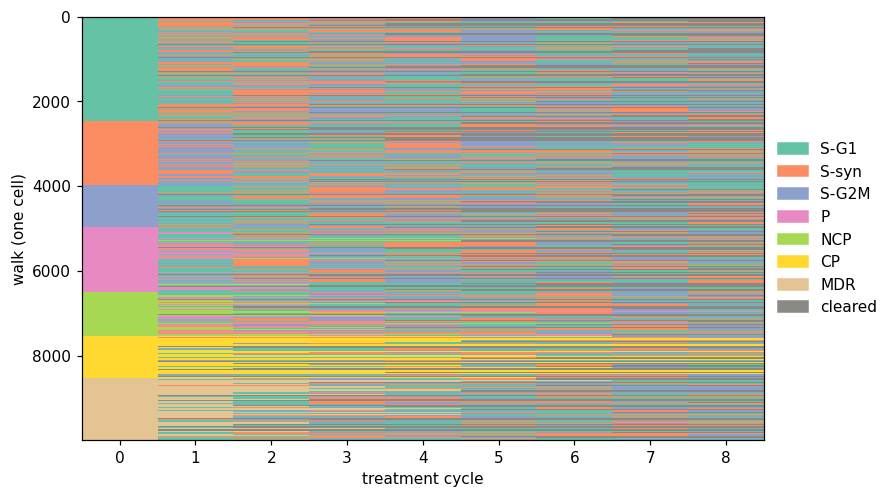

In [32]:
N_WALKS = 10_000
starts = rng.choice(len(pi_mix), size=N_WALKS, p=pi_mix)
walks = np.array([random_walk(int(s0), P, N_CYCLES, rng) for s0 in starts])
walks = walks[np.argsort(walks[:, 0], kind="stable")]   # group rows by starting state

from matplotlib.colors import ListedColormap
fig, ax = plt.subplots(figsize=(8, 5))
ax.imshow(walks, cmap=ListedColormap([STATE_COLORS[s] for s in OUTCOMES]),
          vmin=-0.5, vmax=len(OUTCOMES) - 0.5, aspect="auto", interpolation="nearest")
ax.set_xlabel("treatment cycle"); ax.set_ylabel("walk (one cell)")
handles = [plt.Rectangle((0, 0), 1, 1, color=STATE_COLORS[s]) for s in OUTCOMES]
ax.legend(handles, OUTCOMES, loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
plt.show()

**Compare the two methods.** The fraction of walks in each state at cycle $t$
is an estimate of $\pi_t$. Plot both.

In [33]:
frac = np.array([[np.mean(walks[:, t] == j) for j in range(len(OUTCOMES))]
                 for t in range(N_CYCLES + 1)])

sem = np.array([[np.std(walks[:, t] == j)/np.sqrt(len(walks)) for j in range(len(OUTCOMES))]
                 for t in range(N_CYCLES + 1)])

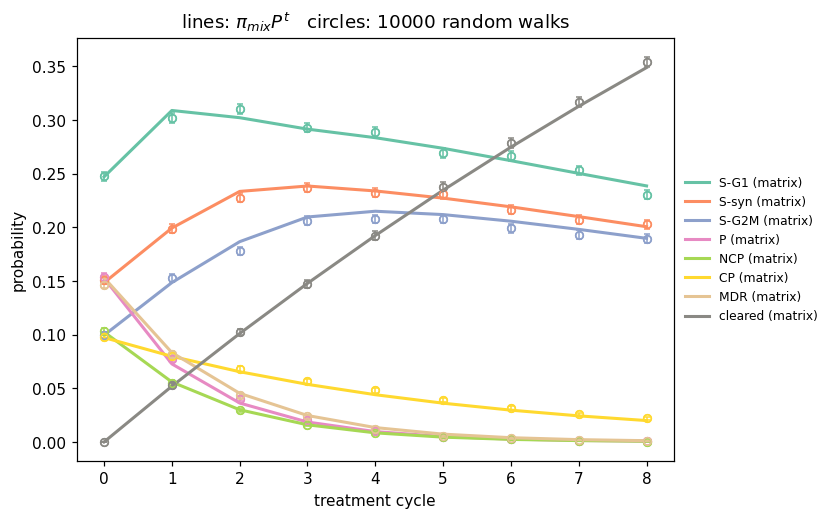

In [34]:
exact = evolve(pi_mix, P, N_CYCLES)
t = np.arange(N_CYCLES + 1)
fig, ax = plt.subplots(figsize=(7, 5))
for j, s in enumerate(OUTCOMES):
    ax.plot(t, exact[:, j], color=STATE_COLORS[s], lw=2, label=f"{s} (matrix)")
    ax.plot(t, frac[:, j], "o", color=STATE_COLORS[s], ms=5, mfc="none")
    ax.errorbar(t, frac[:, j], yerr=sem[:, j], fmt="o", color=STATE_COLORS[s],
            ms=5, mfc="none", capsize=2, elinewidth=1)
ax.set_xlabel("treatment cycle"); ax.set_ylabel("probability")
ax.set_title(f"lines: $\\pi_{{mix}} P^t$   circles: {N_WALKS} random walks")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False, fontsize=8)
plt.show()

We just simulated a tumor with 100 cells in it, and watched how it would evolve under no drug (drug holiday). Let's consider a different sized tumor.

<div class = 'alert alert-info'><b>Question:</b>

Re-run the last three cells with `N_WALKS = 10_000`. How does the gap between the circles and the lines change? Why?</div>

When N_WALKS increases from 100 to 10,000, the circles become much closer to the theoretical lines, and the error bars become smaller. This is because a larger sample size reduces sampling variability. According to the law of large numbers, the simulated proportions approach the theoretical probabilities, while the standard error decreases approximately as $1/\sqrt{N}$.

## 5. What's the probability a drug will clear a tumor?

We've seen in a few different ways how to understand the dynamics of cells within one tumor. We can simulate many tumors in a similar way. This allows us to interpret the likely paths of whole tumors under different treatment options and investigate things like how often cells switch states or linger in the same state.

In [37]:
def simulate_tumor(pi0, P, n_cells, n_cycles, rng):
    '''Return an array of the final state index of each of n_cells cells. Each
    cell's starting state is drawn from pi0.'''
    starts = rng.choice(len(pi0), size=n_cells, p=pi0)
    return np.array([random_walk(int(s0), P, n_cycles, rng)[-1] for s0 in starts])

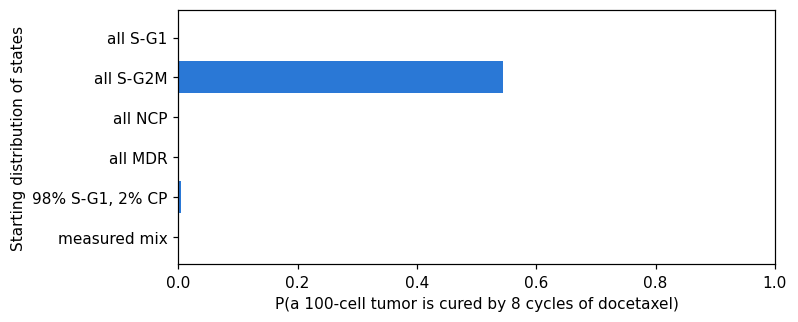

,P(cured),mean surviving cells,share of survivors that are MDR
start,,,
all S-G1,0.000,7.805,0.863
all S-G2M,0.545,0.610,0.631
all NCP,0.000,6.690,0.800
all MDR,0.000,100.000,1.000
"98% S-G1, 2% CP",0.005,6.985,0.866
measured mix,0.000,18.955,0.964


In [38]:
N_CELLS, N_TUMORS = 100, 200
P_TUMOR, N_TUMOR_CYCLES = P_doc, 8      # this simulation: 8 cycles of docetaxel
scenarios = {
    "all S-G1":       basis("S-G1", P_hat),
    "all S-G2M":      basis("S-G2M", P_hat),
    "all NCP":         basis("NCP", P_hat),
    "all MDR":        basis("MDR", P_hat),
    "98% S-G1, 2% CP": 0.98 * basis("S-G1", P_hat) + 0.02 * basis("CP", P_hat),
    "measured mix":   pi_mix,
}
rows = []
for name, pi0 in scenarios.items():
    finals = np.array([simulate_tumor(pi0, P_TUMOR, N_CELLS, N_TUMOR_CYCLES, rng) for _ in range(N_TUMORS)])
    alive = (finals != OUTCOMES.index("cleared")).sum(axis=1)
    rows.append({"start": name,
                 "P(cured)": np.mean(alive == 0),
                 "mean surviving cells": alive.mean(),
                 "share of survivors that are MDR":
                    (finals == OUTCOMES.index("MDR")).sum() / max(alive.sum(), 1)})
results = pd.DataFrame(rows).set_index("start")

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(results.index[::-1], results["P(cured)"][::-1], color="#2a78d6")
ax.set_xlim(0, 1)
ax.set_xlabel(f"P(a {N_CELLS}-cell tumor is cured by {N_TUMOR_CYCLES} cycles of docetaxel)")
ax.set_ylabel("Starting distribution of states")
plt.show()
results.round(3)

<div class="alert alert-info"> Try rerunning the above code with all docetaxel. What do the results look like? </div>

Under eight cycles of docetaxel, tumors starting entirely in S-G2M have the highest cure probability (54.5%). Tumors starting in MDR cannot be cleared because MDR is an absorbing state under docetaxel. Other starting states, such as S-G1 and NCP, also have very low cure probabilities because some cells can transition into MDR and survive treatment. In the measured mix, the cure probability was 0% in our simulation, and 96.4% of the surviving cells were MDR. Compared with osimertinib, docetaxel is less effective for most of the tested tumor compositions. This shows that drug-resistant absorbing states can prevent complete tumor clearance, even when many individual cells are eliminated.

## 6. Investigating the persister state

Something important about the persister cells (P and NCP) not yet included in this model is their ability to pick up *permanent* mutations that allow them to be *permanently resistant (PR).* In other words, if a cell stays in the persister state for too long, it will switch to a new absorbing state not in our data. We don't have this in our dataset, so we can't estimate the transition probability of P -> PR or NCP -> PR to add it to our matrix.

We know that if a cell stays in P or NCP for too long, it will eventually become permanently resistant. We will incorporate this into the model by assuming that **if a P or NCP cell stays in a persister state for 3 or more cycles, it will become permanently resistant.** So we want to look at the random walks of cells themselves and see what percentage of cells in a tumor stay in P or NCP for **3 or more** drug cycles. 

Let's look at 100 tumors of 1000 cells each under osimertinib treatment over 8 cycles. 

In [39]:
rng_pr = np.random.default_rng(42)

N_CELLS = 1000
N_TUMORS = 100
N_CYCLES = 8

PR = len(OUTCOMES)
PERSISTER = [OUTCOMES.index("P"), OUTCOMES.index("NCP")]


def simulate_pr_tumor(pi0, schedule, n_cells, rng):
    # Sample starting states
    states = rng.choice(len(pi0), size=n_cells, p=pi0)

    # Save the full paths
    paths = np.zeros((n_cells, len(schedule) + 1), dtype=int)
    paths[:, 0] = states

    # Track consecutive persister cycles
    streak = np.zeros(n_cells, dtype=int)

    for t, P in enumerate(schedule, start=1):
        active = states != PR

        # Draw the next state for cells not already PR
        current = states[active]
        u = rng.random(len(current))
        cdf = np.cumsum(P[current], axis=1)
        states[active] = np.sum(u[:, None] > cdf, axis=1)

        # Update consecutive persister counts
        is_persister = np.isin(states, PERSISTER)
        streak = np.where(is_persister, streak + 1, 0)

        # Cells reaching 3 cycles become permanently resistant
        states[streak >= 3] = PR

        paths[:, t] = states

    return paths


# Simulate 100 tumors under osimertinib
schedule_osi = [P_osi] * N_CYCLES

pr_fractions = []

for _ in range(N_TUMORS):
    paths = simulate_pr_tumor(
        pi_mix, schedule_osi, N_CELLS, rng_pr
    )

    pr_fraction = np.mean(paths[:, -1] == PR)
    pr_fractions.append(pr_fraction)

pr_fractions = np.array(pr_fractions)

# report mean +/- SEM for osimertinib
# compare to 10% threshold using 95% CI or a hypothesis test
mean_pr = pr_fractions.mean()

sem_pr = pr_fractions.std(ddof=1) / np.sqrt(N_TUMORS)

ci_lower = mean_pr - 1.96 * sem_pr
ci_upper = mean_pr + 1.96 * sem_pr

pct_tumors_above_10 = np.mean(pr_fractions > 0.10) * 100

print(f"Mean PR fraction: {mean_pr:.4f}")
print(f"SEM: {sem_pr:.4f}")
print(f"95% CI: ({ci_lower:.4f}, {ci_upper:.4f})")
print(f"Tumors with >10% PR cells: {pct_tumors_above_10:.1f}%")

Mean PR fraction: 0.0820
SEM: 0.0009
95% CI: (0.0803, 0.0837)
Tumors with >10% PR cells: 2.0%


Under eight cycles of osimertinib, the mean permanently resistant (PR) fraction was 0.0820, with an SEM of 0.0009 and a 95% confidence interval of (0.0803, 0.0837). Since the entire confidence interval is below 0.10, the mean PR fraction is significantly below the 10% threshold. However, 2% of the simulated tumors had more than 10% PR cells, showing that individual tumors can exceed this threshold even when the average is lower.

<div class="alert alert-info"> What percentage of tumors under the following treatments have more than 10% permanently resistant cells? How does this change as you increase the number of cycles?

- Osimertinib alone
- Doxetaxel alone
- Alternating OD
- Doxetaxel with drug holiday
</div>

In [40]:
cycle_options = [4, 8, 12, 16]

treatment_patterns = {
    "Osimertinib": [P_osi],
    "Docetaxel": [P_doc],
    "Alternating O-D": [P_osi, P_doc],
    "Docetaxel + Holiday": [P_doc, P_holiday]
}

rng_compare = np.random.default_rng(42)

comparison_rows = []

for n_cycles in cycle_options:
    for name, pattern in treatment_patterns.items():

        schedule = [
            pattern[t % len(pattern)]
            for t in range(n_cycles)
        ]

        fractions = []

        for _ in range(N_TUMORS):
            paths = simulate_pr_tumor(
                pi_mix, schedule, N_CELLS, rng_compare
            )

            fractions.append(
                np.mean(paths[:, -1] == PR)
            )

        fractions = np.array(fractions)

        comparison_rows.append({
            "Treatment": name,
            "Cycles": n_cycles,
            "Mean PR Fraction": fractions.mean(),
            "Tumors > 10% PR (%)": 100 * np.mean(fractions > 0.10)
        })

pr_comparison = pd.DataFrame(comparison_rows)

display(pr_comparison.round(4))


,Treatment,Cycles,Mean PR Fraction,Tumors > 10% PR (%)
0,Osimertinib,4,0.0780,0.0
1,Docetaxel,4,0.0547,0.0
2,Alternating O-D,4,0.0701,0.0
3,Docetaxel + Holiday,4,0.0490,0.0
4,Osimertinib,8,0.0812,0.0
5,Docetaxel,8,0.0607,0.0
6,Alternating O-D,8,0.0765,0.0
7,Docetaxel + Holiday,8,0.0660,0.0
8,Osimertinib,12,0.0819,1.0
9,Docetaxel,12,0.0601,0.0


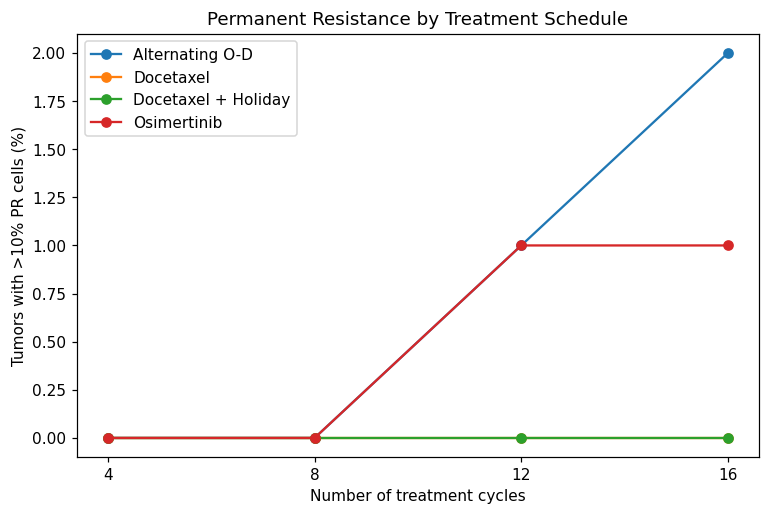

In [41]:
fig, ax = plt.subplots(figsize=(8, 5))

for name, group in pr_comparison.groupby("Treatment"):
    ax.plot(
        group["Cycles"],
        group["Tumors > 10% PR (%)"],
        marker="o",
        label=name
    )

ax.set_xlabel("Number of treatment cycles")
ax.set_ylabel("Tumors with >10% PR cells (%)")
ax.set_title("Permanent Resistance by Treatment Schedule")
ax.set_xticks(cycle_options)
ax.legend()
plt.show()


In our simulation, almost all tumors remained below the 10% permanently resistant (PR) threshold. At 16 cycles, 1% of tumors under osimertinib and 2% under alternating osimertinib-docetaxel exceeded the threshold, while none did under docetaxel alone or docetaxel with drug holidays. The mean PR fraction generally increased as the number of cycles increased. However, the percentages fluctuated slightly due to Monte Carlo sampling variability, since we simulated only 100 tumors for each treatment schedule. Overall, longer treatment can increase the accumulation of permanently resistant cells, but a lower PR fraction does not necessarily mean better tumor clearance because other drug resistant states may still survive.